# ESA Mission 1: dataset analysis

## What the dataset contains

Real satellite telemetry from three ESA missions, annotated by spacecraft operations
engineers and cross-checked by ML experts, published with a benchmark meant to replace
the older spacecraft datasets whose labelling proved unreliable.

**Mission 1**: 76 channels, January 2000 to December 2013.

## Where to download it

> **Zenodo:** <https://doi.org/10.5281/zenodo.12528696>
> **Code:** <https://github.com/kplabs-pl/ESA-ADB> - **Paper:** <https://arxiv.org/abs/2406.17826>

## Structure of the data

Each channel is a separate pickled series on its own irregular
index, reporting every 23 to 906 seconds depending on the channel, median 36.

**The labels are not a column.** `labels.csv` gives intervals covering a stretch of
time *on a particular channel*; `anomaly_types.csv` says whether each is an `Anomaly`,
a `Rare Event` or a `Communication Gap`.

The table below comes from `dencad/data/preprocess/preprocess_esa.py`: every channel
on a common 60-second grid with zero-order hold - each keeps its last reported value
until it reports a new one - and the intervals materialised as per-row labels.


In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import yaml

TABLE = Path("../data/interim/esa/full_esa.parquet")
META = Path("../data/raw/esa/ESA-Mission1")
DECLARED = Path("../data/raw/categorical_columns.yaml")
CATEGORICAL = yaml.safe_load(DECLARED.read_text(encoding="utf-8"))["esa"]
STRIDE = 10
STEP_S = 60                      # the resample grid of preprocess_esa

SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
NORMAL, ANOM = C[0], "#d03b3b"
SEQ = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7",
       "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "grid.linestyle": "-", "axes.axisbelow": True,
    "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.titlesize": 11, "axes.labelsize": 9.5,
    "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 1.6, "figure.dpi": 110,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
})
print("pandas", pd.__version__, "| matplotlib", mpl.__version__)

pandas 3.0.6 | matplotlib 3.11.2


---
## 1. The files

One file, built once over the whole recording.

In [2]:
f = pq.ParquetFile(TABLE)
names = list(f.schema_arrow.names)
channels = [c for c in names if c.startswith("channel_")]
label_cols = [c for c in names if c.startswith("label_")]
flags = [c for c in names if c.startswith("is_")]

print(f"{TABLE.name}: {f.metadata.num_rows:,} rows x {f.metadata.num_columns} columns")
print(f"  {len(channels)} channels, {len(label_cols)} per-channel labels, "
      f"{len(flags)} global flags: {', '.join(flags)}")
print(f"  {f.metadata.num_row_groups} row groups, "
      f"{TABLE.stat().st_size / 2**30:.2f} GB on disk")

lab = pd.read_parquet(TABLE, columns=flags)
step = pd.Series(lab.index).diff().dropna()
print(f"\n  from {lab.index.min()} to {lab.index.max()}")
print(f"  {(lab.index.max() - lab.index.min()).days:,} days at a step of "
      f"{step.median().total_seconds():.0f} s, irregular intervals: "
      f"{int((step != step.median()).sum())}")

full_esa.parquet: 7,364,160 rows x 155 columns
  76 channels, 76 per-channel labels, 2 global flags: is_anomaly, is_rare_event
  19 row groups, 0.24 GB on disk

  from 2000-01-01 00:00:00 to 2013-12-31 23:59:00
  5,113 days at a step of 60 s, irregular intervals: 0


---
## 2. How the recording is ordered

In [3]:

step = np.diff(lab.index.to_numpy()).astype("timedelta64[s]").astype("int64")
print(f"from {lab.index[0]} to {lab.index[-1]}")
print(f"   {len(lab):,} rows over {(lab.index[-1] - lab.index[0]).days:,} days")
print(f"   timestamps unique: {lab.index.is_unique}   monotonic: "
      f"{lab.index.is_monotonic_increasing}")
print(f"   intervals other than {int(np.median(step))} s: {int((step != np.median(step)).sum())}")
print(f"   rows expected from the span: "
      f"{int((lab.index[-1] - lab.index[0]).total_seconds() // np.median(step)) + 1:,}")

from 2000-01-01 00:00:00 to 2013-12-31 23:59:00
   7,364,160 rows over 5,113 days
   timestamps unique: True   monotonic: True
   intervals other than 60 s: 0
   rows expected from the span: 7,364,160


**The axis is exact.** 7,364,160 rows for 7,364,160 expected from the span, not one
interval other than 60 seconds, no repeated timestamp.


---
## 3. Which variables are present

In [4]:
meta = pd.read_csv(META / "channels.csv")
meta = meta[meta["Channel"].isin(channels)].reset_index(drop=True)

print("by subsystem:")
print(meta.groupby("Subsystem").agg(
    channels=("Channel", "size"),
    target=("Target", lambda s: (s == "YES").sum()),
    categorical=("Categorical", lambda s: (s == "YES").sum()),
).to_string())
print(f"\n  scored by the benchmark (Target=YES): {(meta.Target == 'YES').sum()} of {len(meta)}")
print(f"  categorical: {(meta.Categorical == 'YES').sum()}")

by subsystem:
             channels  target  categorical
Subsystem                                 
subsystem_1        17       3            0
subsystem_3        11       7            0
subsystem_5         6       6            0
subsystem_6        42      42            0

  scored by the benchmark (Target=YES): 58 of 76
  categorical: 0


In [5]:

parts = []
for g in range(f.metadata.num_row_groups):
    parts.append(f.read_row_group(g, columns=channels).to_pandas().iloc[::STRIDE])
V = pd.concat(parts)
del parts
print(f"subsample for the statistics below: {len(V):,} rows "
      f"(every {STRIDE}th, {STRIDE * STEP_S} s apart)")

levels = V.nunique()

updates = (V.diff().ne(0) & V.notna()).sum() / V.notna().sum()
summary = pd.DataFrame({"levels": levels, "update rate": updates})
print()
print("distinct values per channel: min %d, median %.0f, max %s"
      % (levels.min(), levels.median(), f"{levels.max():,}"))
print("update rate   : 25%% %.5f | median %.3f | 75%% %.3f"
      % (updates.quantile(.25), updates.median(), updates.quantile(.75)))
print()
print("the ten most static channels:")
print(summary.nsmallest(10, "update rate").to_string())

subsample for the statistics below: 736,416 rows (every 10th, 600 s apart)

distinct values per channel: min 6, median 415, max 7,969
update rate   : 25% 0.22022 | median 0.349 | 75% 0.477

the ten most static channels:
            levels  update rate
channel_11      30     0.000041
channel_10      49     0.000067
channel_9      353     0.000479
channel_8      443     0.000602
channel_2      733     0.001482
channel_1     1022     0.002071
channel_61    1697     0.002307
channel_62    1693     0.002307
channel_63    1692     0.002307
channel_6     2453     0.003331


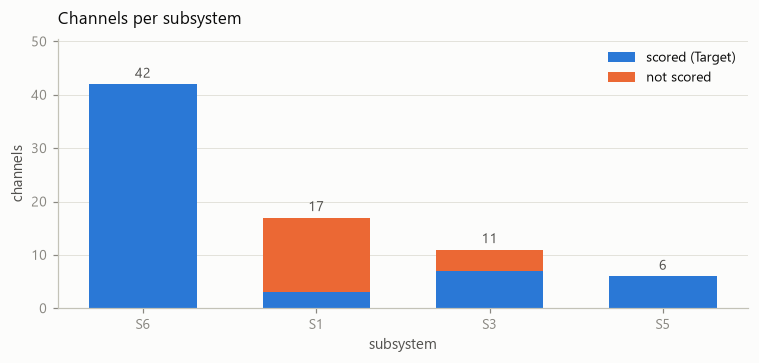

In [6]:
fig, ax1 = plt.subplots(figsize=(7, 3.4))

piv = (meta.assign(scored=np.where(meta.Target == "YES", "scored", "not scored"))
           .groupby(["Subsystem", "scored"]).size().unstack(fill_value=0)
           .reindex(columns=["scored", "not scored"], fill_value=0))
piv = piv.loc[piv.sum(axis=1).sort_values(ascending=False).index]

x = np.arange(len(piv))
ax1.bar(x, piv["scored"], color=C[0], width=0.62, label="scored (Target)")
ax1.bar(x, piv["not scored"], bottom=piv["scored"], color=C[1], width=0.62, label="not scored")

for i, t in enumerate(piv.sum(axis=1)):
    ax1.text(i, t + 1.2, str(int(t)), ha="center", color=INK2, fontsize=9)

ax1.set_xticks(x, [s.replace("subsystem_", "S") for s in piv.index])
ax1.set(xlabel="subsystem", ylabel="channels", title="Channels per subsystem",
        ylim=(0, piv.sum(axis=1).max() * 1.2))
ax1.grid(axis="x", visible=False)
ax1.legend(loc="upper right")

fig.tight_layout()
plt.show()

---
## 4. Data quality



### Where the table has no data

A channel that had not yet reported when the window opened has no value to hold
forward, so those rows are NaN. Nothing else produces one: the raw files have no
missing values, and once a channel starts the hold covers every row to the end.

In [7]:

nan = pd.Series(0, index=channels, dtype="int64")
for g in range(f.metadata.num_row_groups):
    nan += f.read_row_group(g, columns=channels).to_pandas().isna().sum()

N = f.metadata.num_rows
cells = N * len(channels)
print(f"NaN cells: {nan.sum():,} of {cells:,} ({nan.sum() / cells:.3%})")
print(f"  channels with at least one: {int((nan > 0).sum())} of {len(channels)}")
print(f"  channels with none        : {', '.join(nan[nan == 0].index)}")
print()
print("the six channels missing most, in rows and in time:")
for c, v in nan.sort_values(ascending=False).head(6).items():
    print(f"   {c:<12} {v:>9,} rows   {v * STEP_S / 3600:>9.2f} h   {v / N:7.3%} of the table")


print()
print("channels present, cumulatively:")
present = 0
for rows, k in nan.value_counts().sort_index().items():
    present += int(k)
    print(f"   from row {rows:>8,}  (+{str(pd.to_timedelta(rows * STEP_S, unit='s')):>16})  "
          f"{present:>3} channels")

NaN cells: 114 of 559,676,160 (0.000%)
  channels with at least one: 76 of 76
  channels with none        : 

the six channels missing most, in rows and in time:
   channel_61           7 rows        0.12 h    0.000% of the table
   channel_62           7 rows        0.12 h    0.000% of the table
   channel_63           7 rows        0.12 h    0.000% of the table
   channel_65           3 rows        0.05 h    0.000% of the table
   channel_64           3 rows        0.05 h    0.000% of the table
   channel_67           3 rows        0.05 h    0.000% of the table

channels present, cumulatively:
   from row        1  (+ 0 days 00:01:00)   59 channels
   from row        2  (+ 0 days 00:02:00)   67 channels
   from row        3  (+ 0 days 00:03:00)   73 channels
   from row        7  (+ 0 days 00:07:00)   76 channels


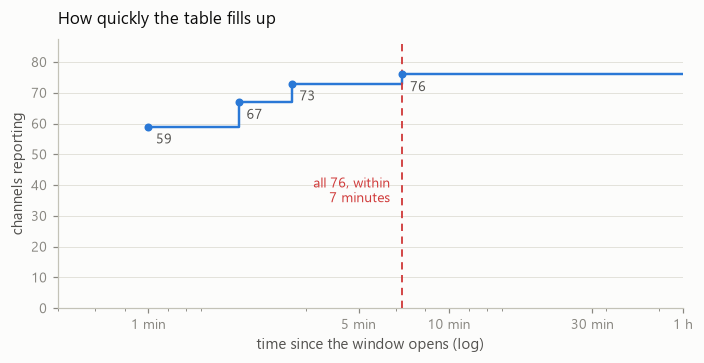

In [8]:
ladder = nan.value_counts().sort_index()
secs = np.clip(ladder.index.to_numpy() * STEP_S, STEP_S / 2, None)
cum = ladder.to_numpy().cumsum()
END = 3600

fig, ax = plt.subplots(figsize=(6.5, 3.4))

ax.step(np.r_[secs, END], np.r_[cum, cum[-1]], where="post", color=C[0])
ax.scatter(secs, cum, s=18, color=C[0], zorder=4)
ax.set_xscale("log")

for x, y in zip(secs, cum):
    ax.annotate(f"{y}", xy=(x, y), xytext=(5, -11), textcoords="offset points",
                color=INK2, fontsize=9)

ax.axvline(secs[-1], color=ANOM, linewidth=1.2, linestyle=(0, (4, 3)), zorder=3)
ax.annotate(f"all {len(channels)}, within\n{secs[-1] / 60:.0f} minutes",
            xy=(secs[-1], cum[-1] * 0.5), xytext=(-8, 0),
            textcoords="offset points", ha="right", va="center",
            color=ANOM, fontsize=9)

ax.set_xlim(STEP_S / 2, END)
ax.set_ylim(0, len(channels) * 1.15)
ax.set_xticks([60, 300, 600, 1800, 3600],
              ["1 min", "5 min", "10 min", "30 min", "1 h"])
ax.set(xlabel="time since the window opens (log)", ylabel="channels reporting",
       title="How quickly the table fills up")
ax.grid(axis="x", visible=False)

fig.tight_layout()
plt.show()

---
## 5. The anomalies


In [25]:
kinds = pd.read_csv(META / "anomaly_types.csv")
print(f"the {len(kinds)} annotations, by category and shape:")
for col in ("Category", "Dimensionality", "Locality", "Length"):
    print(f"  {col:<16} {kinds[col].value_counts().to_dict()}")

def segments(y: np.ndarray):
    ch = np.diff(np.r_[0, (y != 0).astype(int), 0])
    return np.flatnonzero(ch == 1), np.flatnonzero(ch == -1)

a = lab["is_anomaly"].to_numpy()
r = lab["is_rare_event"].to_numpy()
s, e = segments(a)
dur_h = (e - s) * STEP_S / 3600
print()
print(f"anomaly rows    : {int(a.sum()):,} ({a.mean():.3%})")
print(f"rare event rows : {int(r.sum()):,} ({r.mean():.3%})")
print(f"number of anomalous segments: {len(s)}")
print(f"anomalous segment length (hours): min {dur_h.min():.2f} | median {np.median(dur_h):.2f} "
      f"| max {dur_h.max():.1f}")
print()


the 200 annotations, by category and shape:
  Category         {'Anomaly': 118, 'Rare Event': 78, 'Communication Gap': 4}
  Dimensionality   {'Multivariate': 164, 'Univariate': 32}
  Locality         {'Global': 113, 'Local': 83}
  Length           {'Subsequence': 184, 'Point': 12}

anomaly rows    : 299,748 (4.070%)
rare event rows : 475,832 (6.461%)
number of anomalous segments: 106
anomalous segment length (hours): min 0.02 | median 5.48 | max 967.1



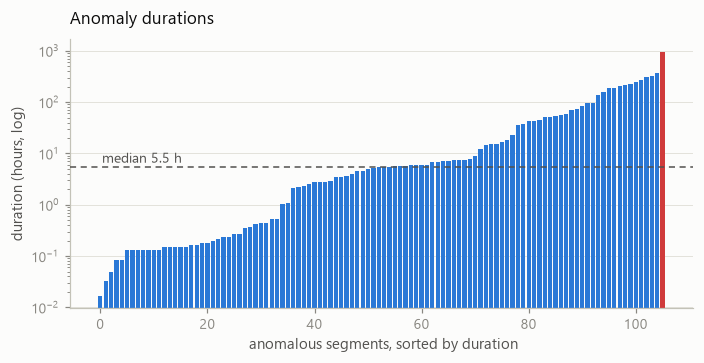

the longest anomalous segment lasts 967.1 hours (40.3 days) and alone covers 19% of all anomalous rows


In [28]:

order = np.sort(dur_h)

fig, ax = plt.subplots(figsize=(6.5, 3.4))

ax.bar(range(len(order)), order, color=C[0], width=0.8)
ax.bar([len(order) - 1], [order[-1]], color=ANOM, width=0.8)
ax.set_yscale("log")
ax.axhline(np.median(dur_h), color=INK2, linewidth=1.0, linestyle=(0, (4, 3)), zorder=3)
ax.text(0.3, np.median(dur_h) * 1.2, f"median {np.median(dur_h):.1f} h",
        color=INK2, fontsize=9)
ax.set(xlabel=" anomalous segments, sorted by duration", ylabel="duration (hours, log)",
       title="Anomaly durations")
ax.grid(axis="x", visible=False)

fig.tight_layout()
plt.show()

share = (e - s).max() / (e - s).sum()
print(f"the longest anomalous segment lasts {dur_h.max():.1f} hours ({dur_h.max()/24:.1f} days) "
      f"and alone covers {share:.0%} of all anomalous rows")

C:\Users\bevia\AppData\Local\Temp\ipykernel_4956\460581141.py:22: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


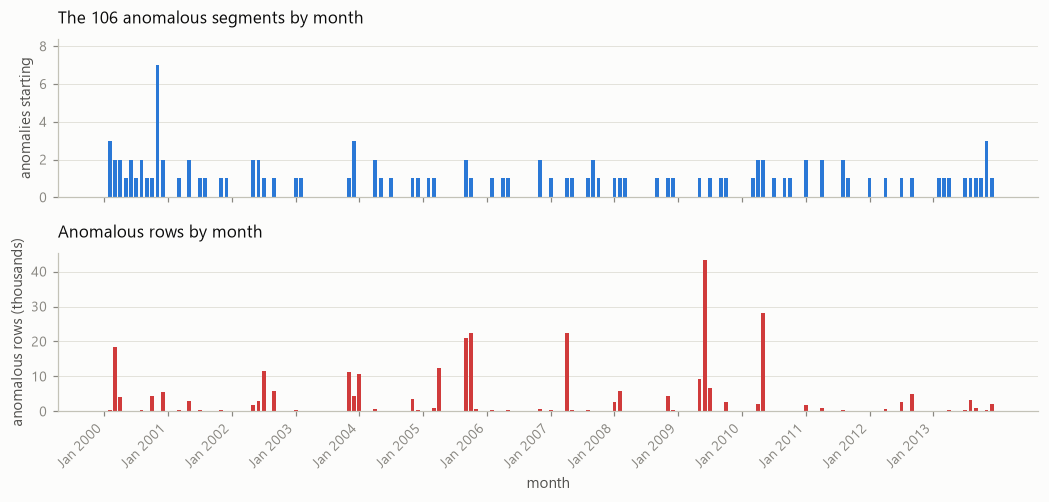

         anomalous segments  anomalous rows share of rows
2000-02                   3             353          0.1%
2000-03                   2           18364          6.1%
2000-04                   2            4247          1.4%
2000-05                   1               9          0.0%
2000-06                   2             164          0.1%
2000-07                   1               2          0.0%
2000-08                   2             338          0.1%
2000-09                   1              10          0.0%
2000-10                   1            4299          1.4%
2000-11                   7              57          0.0%
2000-12                   2            5640          1.9%
2001-03                   1             277          0.1%
2001-05                   2            3039          1.0%
2001-07                   1             440          0.1%
2001-08                   1             175          0.1%
2001-11                   1             405          0.1%
2001-12       

In [32]:

t = lab.index
starts = pd.Series(t[s]).dt.to_period("M")
mass = pd.Series(t[a.astype(bool)]).dt.to_period("M")
span = pd.period_range(t[0].to_period("M"), t[-1].to_period("M"), freq="M")
count = starts.value_counts().reindex(span, fill_value=0)
rows_m = mass.value_counts().reindex(span, fill_value=0)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11.5, 4.4), sharex=True,
                               gridspec_kw={"hspace": 0.35})
x = np.arange(len(span))
ax1.bar(x, count.to_numpy(), color=C[0], width=0.72)
ax1.set(ylabel="anomalies starting", title=f"The {len(s)} anomalous segments by month",
        ylim=(0, max(count.max() * 1.2, 1)))
ax1.grid(axis="x", visible=False)
ax2.bar(x, rows_m.to_numpy() / 1000, color=ANOM, width=0.72)
ax2.set(ylabel="anomalous rows (thousands)", xlabel="month",
        title="Anomalous rows by month")
ax2.grid(axis="x", visible=False)
ticks = [i for i, p in enumerate(span) if p.month == 1]
ax2.set_xticks(ticks, [span[i].strftime("%b %Y") for i in ticks],
               rotation=45, ha="right")
fig.tight_layout()
plt.show()

table = pd.DataFrame({"anomalous segments": count, "anomalous rows": rows_m})
table = table[table.sum(axis=1) > 0]
table["share of rows"] = (table["anomalous rows"] / rows_m.sum()).map("{:.1%}".format)
print(table.to_string())
print()
print(f"{int((count > 0).sum())} of the {len(span)} months contain an anomaly; "
      f"the busiest holds {count.max()} of {len(s)} anomalous segments")

---
## 6. Descriptive statistics


### The continuous channels

In [37]:

FLAGS = ["is_anomaly", "is_rare_event"]
TRAIN = Path("../data/interim/esa/split/esa_train.parquet")
train_end = pd.read_parquet(TRAIN, columns=FLAGS[:1]).index.max()

parts = []
for g in range(f.metadata.num_row_groups):
    blk = f.read_row_group(g, columns=channels + FLAGS,
                           use_pandas_metadata=True).to_pandas()
    blk = blk.loc[blk.index <= train_end]
    if blk.empty:
        break
    keep = (blk[FLAGS[0]] == 0) & (blk[FLAGS[1]] == 0)
    parts.append(blk.loc[keep, channels])
NOM = pd.concat(parts)
del parts

cat_ch = [c for c in channels if c in set(CATEGORICAL)]
con_ch = [c for c in channels if c not in set(CATEGORICAL)]

print(f"training period: {NOM.index.min()} .. {train_end}")
print(f"nominal training rows: {len(NOM):,} ({len(NOM) * len(channels) / 1e6:.0f} M cells)")
print(f"   {len(con_ch)} numeric channels, {len(cat_ch)} categorical "
      f"(as categorical_columns.yaml declares them)")

desc = NOM[con_ch].describe().T
desc[["count", "mean", "std", "min", "50%", "max"]].round(3)

training period: 2000-01-01 00:00:00 .. 2009-09-12 23:59:00
nominal training rows: 4,563,523 (347 M cells)
   76 numeric channels, 0 categorical (as categorical_columns.yaml declares them)


,count,mean,std,min,50%,max
channel_1,4563522.0,0.138,0.001,0.092,0.138,0.433
channel_2,4563522.0,0.126,0.003,0.000,0.126,1.000
channel_3,4563522.0,0.126,0.004,0.000,0.126,1.000
channel_4,4563521.0,0.051,0.022,0.037,0.042,0.191
channel_5,4563521.0,0.049,0.031,0.035,0.040,0.258
...,...,...,...,...,...,...
channel_72,4563522.0,0.824,0.004,0.000,0.823,0.839
channel_73,4563522.0,0.938,0.005,0.000,0.938,0.954
channel_74,4563522.0,0.984,0.004,0.974,0.984,0.999
channel_75,4563522.0,0.910,0.003,0.000,0.909,0.923


### The categorical channels

There are none. `channels.csv` marks no channel `Categorical`.


### Pearson, on the continuous channels

numeric channels with variance in nominal operation: 76 of 76


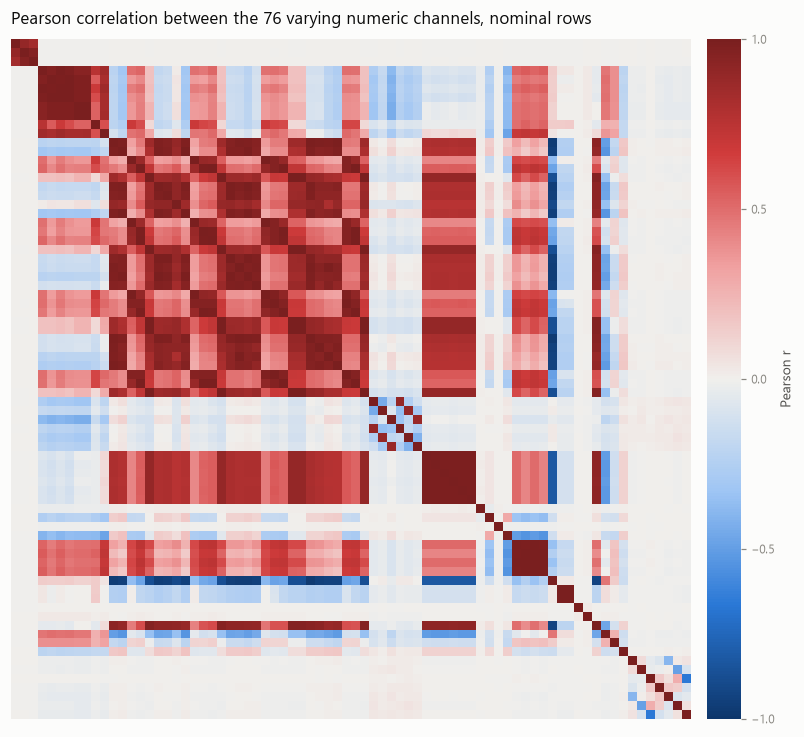

2,850 distinct pairs   median |r| = 0.113   |r| > 0.8: 12.5%   |r| > 0.5: 23.6%

most strongly correlated pairs:
   channel_8    ~ channel_9    r = +1.0000   same subsystem
   channel_63   ~ channel_62   r = +1.0000   same subsystem
   channel_22   ~ channel_31   r = +0.9991   same subsystem
   channel_15   ~ channel_23   r = +0.9990   same subsystem
   channel_38   ~ channel_30   r = +0.9990   same subsystem
   channel_14   ~ channel_21   r = +0.9989   same subsystem
   channel_40   ~ channel_33   r = +0.9986   same subsystem
   channel_16   ~ channel_32   r = +0.9986   same subsystem
   channel_32   ~ channel_40   r = +0.9986   same subsystem
   channel_33   ~ channel_16   r = +0.9986   same subsystem


In [38]:
sd = V.loc[nominal, con_ch].std()
numeric = [c for c in con_ch if sd[c] > 1e-9]
dropped = [c for c in con_ch if sd[c] <= 1e-9]
print(f"numeric channels with variance in nominal operation: {len(numeric)} "
      f"of {len(con_ch)}")
if dropped:
    print("  dropped as constant:", ", ".join(dropped))

corr = V.loc[nominal, numeric].corr()          # method="pearson" is the default

fig, ax = plt.subplots(figsize=(8.0, 6.8))
div = mpl.colors.LinearSegmentedColormap.from_list(
    "div", ["#0d366b", "#2a78d6", "#9ec5f4", "#f0efec", "#f0a0a0", "#d03b3b", "#7a1f1f"])
im = ax.imshow(corr.values, cmap=div, vmin=-1, vmax=1, aspect="equal")
ax.set_xticks([]); ax.set_yticks([])
ax.set_title(f"Pearson correlation between the {len(numeric)} varying numeric "
             f"channels, nominal rows")
ax.grid(visible=False)
for sp in ax.spines.values():
    sp.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.02, ticks=[-1, -0.5, 0, 0.5, 1])
cb.set_label("Pearson r", color=INK2, fontsize=9)
cb.ax.tick_params(colors=MUTED, labelsize=8)
cb.outline.set_visible(False)
fig.tight_layout()
plt.show()

vals = np.abs(corr.values[np.triu_indices(len(corr), 1)])
print(f"{len(vals):,} distinct pairs   median |r| = {np.median(vals):.3f}   "
      f"|r| > 0.8: {(vals > 0.8).mean():.1%}   |r| > 0.5: {(vals > 0.5).mean():.1%}")

off = corr.where(~np.eye(len(corr), dtype=bool)).stack().sort_values(key=abs, ascending=False)
seen, top = set(), []
for (i, j), v in off.items():
    if (j, i) in seen:
        continue
    seen.add((i, j)); top.append((i, j, float(v)))
    if len(top) == 10:
        break
sub = dict(zip(meta.Channel, meta.Subsystem))
print("\nmost strongly correlated pairs:")
for i, j, v in top:
    same = "same subsystem" if sub.get(i) == sub.get(j) else "across subsystems"
    print(f"   {i:<12} ~ {j:<12} r = {v:+.4f}   {same}")

---
## 7. Summary

**The dataset.** 76 channels of expert-annotated satellite telemetry over fourteen years,
delivered as per-channel series on irregular indices and reassembled here onto one
60-second grid with zero-order hold.

**What has to be handled.**

| issue | detail |
|---|---|
| no table in the raw data | 76 channels on independent indices, reporting every 23 to 906 seconds |
| labels are intervals, not a column | `(ID, Channel, StartTime, EndTime)` plus a category, materialised per row |
| 78 of the 200 annotations are not anomalies | `Rare Event` is unusual but nominal, so counting it as a positive changes the task; the pipeline therefore builds both labels |
| four channels are near-constant | they change on under one row in a thousand |
| channels are duplicated | 12.5% of the 2,850 pairs correlate above 0.8 and several reach 1.0000, so the processing step drops one of each pair |

**What makes it tractable.**

- The annotation is **per channel**: attribution becomes measurable.
- Annotations are overwhelmingly **multivariate**, 164 of 196.
